# APEX — Formula 1 Top-10 Prediction

APEX это проект в области машинного обучения, предназначенный для прогнозирования того, финиширует ли пилот «Формулы-1» в первой десятке
В проекте используются исторические данные «Формулы-1» за сезоны 2022–2024 годов

Модель обучается на данных сезонов 2022–2023 годов, а ее оценка проводится на данных сезона 2024 года с использованием временного разделения выборки на обучающую и тестовую

Основная цель — сравнить подход на основе машинного обучения с простым базовым методом, опирающимся на стартовую позицию


In [1]:
import pandas as pd

file_path = "data/processed/f1_race_results_2022_2024.csv"

df = pd.read_csv(file_path)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False))

print("\nDuplicates:", df.duplicated().sum())

Shape: (1359, 24)

Columns:
['DriverNumber', 'BroadcastName', 'Abbreviation', 'DriverId', 'TeamName', 'TeamColor', 'TeamId', 'FirstName', 'LastName', 'FullName', 'HeadshotUrl', 'CountryCode', 'Position', 'ClassifiedPosition', 'GridPosition', 'Q1', 'Q2', 'Q3', 'Time', 'Status', 'Points', 'Laps', 'Year', 'Round']

Missing values:


Q2                    1359
Q3                    1359
Q1                    1359
Time                   280
HeadshotUrl             58
BroadcastName            2
GridPosition             2
TeamColor                2
Position                 2
CountryCode              2
FirstName                0
TeamId                   0
DriverNumber             0
Abbreviation             0
TeamName                 0
DriverId                 0
ClassifiedPosition       0
LastName                 0
FullName                 0
Status                   0
Points                   0
Laps                     0
Year                     0
Round                    0
dtype: int64


Duplicates: 0


In [2]:
df["top10"] = (df["Position"] <= 10).astype(int)

print(df["top10"].value_counts())
print()
print(df[["Position", "GridPosition", "top10"]].head(20))

top10
1    680
0    679
Name: count, dtype: int64

    Position  GridPosition  top10
0        1.0           1.0      1
1        2.0           3.0      1
2        3.0           5.0      1
3        4.0           9.0      1
4        5.0           7.0      1
5        6.0           6.0      1
6        7.0          11.0      1
7        8.0          16.0      1
8        9.0           8.0      1
9       10.0          15.0      1
10      11.0          12.0      0
11      12.0          19.0      0
12      13.0          14.0      0
13      14.0          18.0      0
14      15.0          13.0      0
15      16.0          20.0      0
16      17.0          17.0      0
17      18.0           4.0      0
18      19.0           2.0      0
19      20.0          10.0      0


In [3]:
# Колонки для модели

model_df = df[
    [
        "DriverId",
        "Abbreviation",
        "FullName",
        "TeamName",
        "Position",
        "GridPosition",
        "Status",
        "Points",
        "Laps",
        "Year",
        "Round",
        "top10"
    ]
].copy()

print("Shape:", model_df.shape)
display(model_df.head())

Shape: (1359, 12)


,DriverId,Abbreviation,FullName,TeamName,Position,GridPosition,Status,Points,Laps,Year,Round,top10
0,leclerc,LEC,Charles Leclerc,Ferrari,1.0,1.0,Finished,26.0,57.0,2022,1,1
1,sainz,SAI,Carlos Sainz,Ferrari,2.0,3.0,Finished,18.0,57.0,2022,1,1
2,hamilton,HAM,Lewis Hamilton,Mercedes,3.0,5.0,Finished,15.0,57.0,2022,1,1
3,russell,RUS,George Russell,Mercedes,4.0,9.0,Finished,12.0,57.0,2022,1,1
4,kevin_magnussen,MAG,Kevin Magnussen,Haas F1 Team,5.0,7.0,Finished,10.0,57.0,2022,1,1


In [4]:
model_df = model_df.rename(columns={
    "DriverId": "driver_id",
    "Abbreviation": "driver",
    "FullName": "driver_name",
    "TeamName": "team",
    "Position": "finish_position",
    "GridPosition": "grid_position",
    "Status": "status",
    "Points": "race_points",
    "Laps": "laps",
    "Year": "year",
    "Round": "round"
})

print(model_df.columns.tolist())
display(model_df.head())

['driver_id', 'driver', 'driver_name', 'team', 'finish_position', 'grid_position', 'status', 'race_points', 'laps', 'year', 'round', 'top10']


,driver_id,driver,driver_name,team,finish_position,grid_position,status,race_points,laps,year,round,top10
0,leclerc,LEC,Charles Leclerc,Ferrari,1.0,1.0,Finished,26.0,57.0,2022,1,1
1,sainz,SAI,Carlos Sainz,Ferrari,2.0,3.0,Finished,18.0,57.0,2022,1,1
2,hamilton,HAM,Lewis Hamilton,Mercedes,3.0,5.0,Finished,15.0,57.0,2022,1,1
3,russell,RUS,George Russell,Mercedes,4.0,9.0,Finished,12.0,57.0,2022,1,1
4,kevin_magnussen,MAG,Kevin Magnussen,Haas F1 Team,5.0,7.0,Finished,10.0,57.0,2022,1,1


In [5]:
print(model_df.dtypes)

driver_id           object
driver              object
driver_name         object
team                object
finish_position    float64
grid_position      float64
status              object
race_points        float64
laps               float64
year                 int64
round                int64
top10                int64
dtype: object


In [6]:
model_df = model_df.sort_values(
    ["year", "round", "finish_position"]
).reset_index(drop=True)

display(
    model_df[
        ["year", "round", "driver", "team", "finish_position", "grid_position", "top10"]
    ].head(20)
)

,year,round,driver,team,finish_position,grid_position,top10
0,2022,1,LEC,Ferrari,1.0,1.0,1
1,2022,1,SAI,Ferrari,2.0,3.0,1
2,2022,1,HAM,Mercedes,3.0,5.0,1
3,2022,1,RUS,Mercedes,4.0,9.0,1
4,2022,1,MAG,Haas F1 Team,5.0,7.0,1
5,2022,1,BOT,Alfa Romeo,6.0,6.0,1
6,2022,1,OCO,Alpine,7.0,11.0,1
7,2022,1,TSU,AlphaTauri,8.0,16.0,1
8,2022,1,ALO,Alpine,9.0,8.0,1
9,2022,1,ZHO,Alfa Romeo,10.0,15.0,1


In [7]:
print("Top 10 distribution:")
print(model_df["top10"].value_counts())

print("\nTop 10 percentage:")
print(model_df["top10"].mean())

Top 10 distribution:
top10
1    680
0    679
Name: count, dtype: int64

Top 10 percentage:
0.5003679175864606


In [8]:
print(
    model_df[model_df["grid_position"].isna()][
        ["year", "round", "driver", "team", "finish_position", "grid_position"]
    ]
)

     year  round driver          team  finish_position  grid_position
39   2022      2    MSC  Haas F1 Team              NaN            NaN
739  2023     15    STR  Aston Martin              NaN            NaN


In [9]:
print("Top-10 distribution:")
print(model_df["top10"].value_counts(dropna=False))

print("\nTop-10 rate:")
print(model_df["top10"].mean())

Top-10 distribution:
top10
1    680
0    679
Name: count, dtype: int64

Top-10 rate:
0.5003679175864606


In [10]:
model_df["previous_race_position"] = (
    model_df
    .groupby("driver_id")["finish_position"]
    .shift(1)
)

model_df["previous_race_points"] = (
    model_df
    .groupby("driver_id")["race_points"]
    .shift(1)
)

display(
    model_df[
        [
            "year",
            "round",
            "driver",
            "finish_position",
            "previous_race_position",
            "race_points",
            "previous_race_points"
        ]
    ].head(30)
)

,year,round,driver,finish_position,previous_race_position,race_points,previous_race_points
0,2022,1,LEC,1.0,NaN,26.0,NaN
1,2022,1,SAI,2.0,NaN,18.0,NaN
2,2022,1,HAM,3.0,NaN,15.0,NaN
3,2022,1,RUS,4.0,NaN,12.0,NaN
4,2022,1,MAG,5.0,NaN,10.0,NaN
5,2022,1,BOT,6.0,NaN,8.0,NaN
6,2022,1,OCO,7.0,NaN,6.0,NaN
7,2022,1,TSU,8.0,NaN,4.0,NaN
8,2022,1,ALO,9.0,NaN,2.0,NaN
9,2022,1,ZHO,10.0,NaN,1.0,NaN


In [11]:
model_df["driver_avg_finish_last_3"] = (
    model_df
    .groupby("driver_id")["finish_position"]
    .transform(
        lambda x: x.shift(1).rolling(3, min_periods=1).mean()
    )
)

display(
    model_df[
        [
            "year",
            "round",
            "driver",
            "finish_position",
            "driver_avg_finish_last_3"
        ]
    ].head(30)
)

,year,round,driver,finish_position,driver_avg_finish_last_3
0,2022,1,LEC,1.0,NaN
1,2022,1,SAI,2.0,NaN
2,2022,1,HAM,3.0,NaN
3,2022,1,RUS,4.0,NaN
4,2022,1,MAG,5.0,NaN
5,2022,1,BOT,6.0,NaN
6,2022,1,OCO,7.0,NaN
7,2022,1,TSU,8.0,NaN
8,2022,1,ALO,9.0,NaN
9,2022,1,ZHO,10.0,NaN


In [16]:
model_df["driver_avg_finish_last_5"] = (
    model_df
    .groupby("driver_id")["finish_position"]
    .transform(
        lambda x: x.shift(1).rolling(5, min_periods=1).mean()
    )
)

model_df["driver_avg_points_last_5"] = (
    model_df
    .groupby("driver_id")["race_points"]
    .transform(
        lambda x: x.shift(1).rolling(5, min_periods=1).mean()
    )
)

model_df["driver_top10_rate_last_5"] = (
    model_df
    .groupby("driver_id")["top10"]
    .transform(
        lambda x: x.shift(1).rolling(5, min_periods=1).mean()
    )
)

display(
    model_df[
        [
            "year",
            "round",
            "driver",
            "finish_position",
            "driver_avg_finish_last_5"
        ]
    ].head(30)
)

,year,round,driver,finish_position,driver_avg_finish_last_5
0,2022,1,LEC,1.0,NaN
1,2022,1,SAI,2.0,NaN
2,2022,1,HAM,3.0,NaN
3,2022,1,RUS,4.0,NaN
4,2022,1,MAG,5.0,NaN
5,2022,1,BOT,6.0,NaN
6,2022,1,OCO,7.0,NaN
7,2022,1,TSU,8.0,NaN
8,2022,1,ALO,9.0,NaN
9,2022,1,ZHO,10.0,NaN


In [17]:
feature_columns = [
    "previous_race_position",
    "previous_race_points",
    "driver_avg_finish_last_3",
    "driver_avg_finish_last_5",
    "driver_avg_points_last_5",
    "driver_top10_rate_last_5"
]

display(
    model_df[
        ["year", "round", "driver", "finish_position"] + feature_columns
    ].head(40)
)

,year,round,driver,finish_position,previous_race_position,previous_race_points,driver_avg_finish_last_3,driver_avg_finish_last_5,driver_avg_points_last_5,driver_top10_rate_last_5
0,2022,1,LEC,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,2022,1,SAI,2.0,NaN,NaN,NaN,NaN,NaN,NaN
2,2022,1,HAM,3.0,NaN,NaN,NaN,NaN,NaN,NaN
3,2022,1,RUS,4.0,NaN,NaN,NaN,NaN,NaN,NaN
4,2022,1,MAG,5.0,NaN,NaN,NaN,NaN,NaN,NaN
5,2022,1,BOT,6.0,NaN,NaN,NaN,NaN,NaN,NaN
6,2022,1,OCO,7.0,NaN,NaN,NaN,NaN,NaN,NaN
7,2022,1,TSU,8.0,NaN,NaN,NaN,NaN,NaN,NaN
8,2022,1,ALO,9.0,NaN,NaN,NaN,NaN,NaN,NaN
9,2022,1,ZHO,10.0,NaN,NaN,NaN,NaN,NaN,NaN


In [18]:
model_df["team_avg_finish_last_3"] = (
    model_df
    .groupby("team")["finish_position"]
    .transform(
        lambda x: x.shift(1).rolling(3, min_periods=1).mean()
    )
)

In [19]:
model_df["team_avg_finish_last_5"] = (
    model_df
    .groupby("team")["finish_position"]
    .transform(
        lambda x: x.shift(1).rolling(5, min_periods=1).mean()
    )
)

model_df["team_avg_points_last_5"] = (
    model_df
    .groupby("team")["race_points"]
    .transform(
        lambda x: x.shift(1).rolling(5, min_periods=1).mean()
    )
)

In [20]:
team_features = [
    "team_avg_finish_last_3",
    "team_avg_finish_last_5",
    "team_avg_points_last_5"
]

display(
    model_df[
        [
            "year",
            "round",
            "driver",
            "team",
            "finish_position"
        ] + team_features
    ].head(40)
)

,year,round,driver,team,finish_position,team_avg_finish_last_3,team_avg_finish_last_5,team_avg_points_last_5
0,2022,1,LEC,Ferrari,1.0,NaN,NaN,NaN
1,2022,1,SAI,Ferrari,2.0,1.000000,1.000000,26.000000
2,2022,1,HAM,Mercedes,3.0,NaN,NaN,NaN
3,2022,1,RUS,Mercedes,4.0,3.000000,3.000000,15.000000
4,2022,1,MAG,Haas F1 Team,5.0,NaN,NaN,NaN
5,2022,1,BOT,Alfa Romeo,6.0,NaN,NaN,NaN
6,2022,1,OCO,Alpine,7.0,NaN,NaN,NaN
7,2022,1,TSU,AlphaTauri,8.0,NaN,NaN,NaN
8,2022,1,ALO,Alpine,9.0,7.000000,7.000000,6.000000
9,2022,1,ZHO,Alfa Romeo,10.0,6.000000,6.000000,8.000000


In [25]:
import fastf1
import pandas as pd

seasons = {
    2022: 22,
    2023: 22,
    2024: 24
}

race_events = []

for year, last_round in seasons.items():

    for round_number in range(1, last_round + 1):

        session = fastf1.get_session(year, round_number, "R")
        session.load(
            telemetry=False,
            weather=False,
            messages=False
        )

        race_events.append({
            "year": year,
            "round": round_number,
            "event_name": session.event.EventName
        })

race_events_df = pd.DataFrame(race_events)

display(race_events_df.head(10))
print("Races:", len(race_events_df))

req         WARNING 	DEFAULT CACHE ENABLED! (3.27 GB) C:\Users\Admin\AppData\Local\Temp\fastf1
core           INFO 	Loading data for Bahrain Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core        WARNING 	Driver 16 completed the race distance 00:00.050000 before the recorded end of the session.
core           INFO 	Finished loading data for 20 drivers: ['16', '55', '44', '63', '20', '77', '31', '22', '14', '24', '47', '18', '23', '3', '4', '6', '27', '11', '1', '10']
core           INFO 	Loading data for Saudi Arabian Grand Prix - Race [v3.8.3]
req   

,year,round,event_name
0,2022,1,Bahrain Grand Prix
1,2022,2,Saudi Arabian Grand Prix
2,2022,3,Australian Grand Prix
3,2022,4,Emilia Romagna Grand Prix
4,2022,5,Miami Grand Prix
5,2022,6,Spanish Grand Prix
6,2022,7,Monaco Grand Prix
7,2022,8,Azerbaijan Grand Prix
8,2022,9,Canadian Grand Prix
9,2022,10,British Grand Prix


Races: 68


In [27]:
# Добавляем название трассы/этапа к model_df

model_df = model_df.merge(
    race_events_df,
    on=["year", "round"],
    how="left"
)

display(
    model_df[
        ["year", "round", "driver", "event_name"]
    ].head(20)
)

print("event_name missing:", model_df["event_name"].isna().sum())

,year,round,driver,event_name
0,2022,1,LEC,Bahrain Grand Prix
1,2022,1,SAI,Bahrain Grand Prix
2,2022,1,HAM,Bahrain Grand Prix
3,2022,1,RUS,Bahrain Grand Prix
4,2022,1,MAG,Bahrain Grand Prix
5,2022,1,BOT,Bahrain Grand Prix
6,2022,1,OCO,Bahrain Grand Prix
7,2022,1,TSU,Bahrain Grand Prix
8,2022,1,ALO,Bahrain Grand Prix
9,2022,1,ZHO,Bahrain Grand Prix


event_name missing: 0


In [29]:
model_df["driver_races_at_circuit"] = (
    model_df
    .groupby(["driver_id", "event_name"])
    .cumcount()
)

display(
    model_df[
        [
            "year",
            "round",
            "driver",
            "event_name",
            "driver_races_at_circuit"
        ]
    ].head(20)
)

,year,round,driver,event_name,driver_races_at_circuit
0,2022,1,LEC,Bahrain Grand Prix,0
1,2022,1,SAI,Bahrain Grand Prix,0
2,2022,1,HAM,Bahrain Grand Prix,0
3,2022,1,RUS,Bahrain Grand Prix,0
4,2022,1,MAG,Bahrain Grand Prix,0
5,2022,1,BOT,Bahrain Grand Prix,0
6,2022,1,OCO,Bahrain Grand Prix,0
7,2022,1,TSU,Bahrain Grand Prix,0
8,2022,1,ALO,Bahrain Grand Prix,0
9,2022,1,ZHO,Bahrain Grand Prix,0


In [30]:
model_df["team_avg_finish_at_circuit"] = (
    model_df
    .groupby(["team", "event_name"])["finish_position"]
    .transform(
        lambda x: x.shift(1).expanding().mean()
    )
)

display(
    model_df[
        [
            "year",
            "round",
            "driver",
            "team",
            "event_name",
            "team_avg_finish_at_circuit"
        ]
    ].head(20)
)

,year,round,driver,team,event_name,team_avg_finish_at_circuit
0,2022,1,LEC,Ferrari,Bahrain Grand Prix,NaN
1,2022,1,SAI,Ferrari,Bahrain Grand Prix,1.0
2,2022,1,HAM,Mercedes,Bahrain Grand Prix,NaN
3,2022,1,RUS,Mercedes,Bahrain Grand Prix,3.0
4,2022,1,MAG,Haas F1 Team,Bahrain Grand Prix,NaN
5,2022,1,BOT,Alfa Romeo,Bahrain Grand Prix,NaN
6,2022,1,OCO,Alpine,Bahrain Grand Prix,NaN
7,2022,1,TSU,AlphaTauri,Bahrain Grand Prix,NaN
8,2022,1,ALO,Alpine,Bahrain Grand Prix,7.0
9,2022,1,ZHO,Alfa Romeo,Bahrain Grand Prix,6.0


In [33]:
import os

cache_path = "cache"

for root, dirs, files in os.walk(cache_path):
    q_files = [f for f in files if "qualifying" in f.lower() or "session" in f.lower()]
    if q_files:
        print(root)
        print(q_files[:10])

cache\2022\2022-03-20_Bahrain_Grand_Prix\2022-03-20_Race
['session_info.ff1pkl', 'session_status_data.ff1pkl']
cache\2022\2022-03-27_Saudi_Arabian_Grand_Prix\2022-03-27_Race
['session_info.ff1pkl', 'session_status_data.ff1pkl']
cache\2022\2022-04-10_Australian_Grand_Prix\2022-04-10_Race
['session_info.ff1pkl', 'session_status_data.ff1pkl']
cache\2022\2022-04-24_Emilia_Romagna_Grand_Prix\2022-04-24_Race
['session_info.ff1pkl', 'session_status_data.ff1pkl']
cache\2022\2022-05-08_Miami_Grand_Prix\2022-05-08_Race
['session_info.ff1pkl', 'session_status_data.ff1pkl']
cache\2022\2022-05-22_Spanish_Grand_Prix\2022-05-22_Race
['session_info.ff1pkl', 'session_status_data.ff1pkl']
cache\2022\2022-05-29_Monaco_Grand_Prix\2022-05-29_Race
['session_info.ff1pkl', 'session_status_data.ff1pkl']
cache\2022\2022-06-12_Azerbaijan_Grand_Prix\2022-06-12_Race
['session_info.ff1pkl', 'session_status_data.ff1pkl']
cache\2022\2022-06-19_Canadian_Grand_Prix\2022-06-19_Race
['session_info.ff1pkl', 'session_statu

In [34]:


team_race = (
    model_df
    .groupby(["year", "round", "team"], as_index=False)
    .agg(
        team_race_avg_finish=("finish_position", "mean"),
        team_race_points=("race_points", "sum")
    )
) #агрегируем результаты команды на уровне гонки

display(team_race.head(10))
print("Team-race rows:", len(team_race))

,year,round,team,team_race_avg_finish,team_race_points
0,2022,1,Alfa Romeo,8.0,9.0
1,2022,1,AlphaTauri,14.0,4.0
2,2022,1,Alpine,8.0,8.0
3,2022,1,Aston Martin,14.5,0.0
4,2022,1,Ferrari,1.5,44.0
5,2022,1,Haas F1 Team,8.0,10.0
6,2022,1,McLaren,14.5,0.0
7,2022,1,Mercedes,3.5,27.0
8,2022,1,Red Bull Racing,18.5,0.0
9,2022,1,Williams,14.5,0.0


Team-race rows: 680


In [35]:
#форма команды за предыдущие гонки

team_race = team_race.sort_values(
    ["team", "year", "round"]
).reset_index(drop=True)

team_race["team_avg_finish_last_3"] = (
    team_race
    .groupby("team")["team_race_avg_finish"]
    .transform(
        lambda x: x.shift(1).rolling(3, min_periods=1).mean()
    )
)

team_race["team_avg_finish_last_5"] = (
    team_race
    .groupby("team")["team_race_avg_finish"]
    .transform(
        lambda x: x.shift(1).rolling(5, min_periods=1).mean()
    )
)

team_race["team_avg_points_last_5"] = (
    team_race
    .groupby("team")["team_race_points"]
    .transform(
        lambda x: x.shift(1).rolling(5, min_periods=1).mean()
    )
)

display(
    team_race[
        [
            "year",
            "round",
            "team",
            "team_avg_finish_last_3",
            "team_avg_finish_last_5",
            "team_avg_points_last_5"
        ]
    ].head(20)
)

,year,round,team,team_avg_finish_last_3,team_avg_finish_last_5,team_avg_points_last_5
0,2022,1,Alfa Romeo,NaN,NaN,NaN
1,2022,2,Alfa Romeo,8.000000,8.000000,9.000000
2,2022,3,Alfa Romeo,10.500000,10.500000,4.500000
3,2022,4,Alfa Romeo,10.166667,10.166667,4.333333
4,2022,5,Alfa Romeo,10.833333,10.125000,5.750000
5,2022,6,Alfa Romeo,11.000000,10.800000,5.800000
6,2022,7,Alfa Romeo,12.000000,11.700000,5.600000
7,2022,8,Alfa Romeo,12.833333,11.600000,6.000000
8,2022,9,Alfa Romeo,13.166667,12.600000,5.200000
9,2022,10,Alfa Romeo,11.500000,12.100000,5.200000


In [37]:
#добавляем исторические показатели команды в model_df

team_features = team_race[
    [
        "year",
        "round",
        "team",
        "team_avg_finish_last_3",
        "team_avg_finish_last_5",
        "team_avg_points_last_5"
    ]
].copy()

model_df = model_df.drop(
    columns=[
        "team_avg_finish_last_3",
        "team_avg_finish_last_5",
        "team_avg_points_last_5"
    ],
    errors="ignore"
)

model_df = model_df.merge(
    team_features,
    on=["year", "round", "team"],
    how="left"
)

display(
    model_df[
        [
            "year",
            "round",
            "driver",
            "team",
            "team_avg_finish_last_3",
            "team_avg_finish_last_5",
            "team_avg_points_last_5"
        ]
    ].head(20)
)

,year,round,driver,team,team_avg_finish_last_3,team_avg_finish_last_5,team_avg_points_last_5
0,2022,1,LEC,Ferrari,NaN,NaN,NaN
1,2022,1,SAI,Ferrari,NaN,NaN,NaN
2,2022,1,HAM,Mercedes,NaN,NaN,NaN
3,2022,1,RUS,Mercedes,NaN,NaN,NaN
4,2022,1,MAG,Haas F1 Team,NaN,NaN,NaN
5,2022,1,BOT,Alfa Romeo,NaN,NaN,NaN
6,2022,1,OCO,Alpine,NaN,NaN,NaN
7,2022,1,TSU,AlphaTauri,NaN,NaN,NaN
8,2022,1,ALO,Alpine,NaN,NaN,NaN
9,2022,1,ZHO,Alfa Romeo,NaN,NaN,NaN


In [42]:
model_df["driver_avg_finish_at_circuit"] = (
    model_df
    .groupby(["driver_id", "event_name"])["finish_position"]
    .transform(
        lambda x: x.shift(1).expanding().mean()
    )
)

model_df["driver_races_at_circuit"] = (
    model_df
    .groupby(["driver_id", "event_name"])
    .cumcount()
)

print("Circuit features created.")

Circuit features created.


In [43]:
print(
    model_df[
        [
            "driver_avg_finish_at_circuit",
            "driver_races_at_circuit"
        ]
    ].head(20)
)

    driver_avg_finish_at_circuit  driver_races_at_circuit
0                            NaN                        0
1                            NaN                        0
2                            NaN                        0
3                            NaN                        0
4                            NaN                        0
5                            NaN                        0
6                            NaN                        0
7                            NaN                        0
8                            NaN                        0
9                            NaN                        0
10                           NaN                        0
11                           NaN                        0
12                           NaN                        0
13                           NaN                        0
14                           NaN                        0
15                           NaN                        0
16            

In [44]:
team_circuit = (
    model_df
    .groupby(
        ["year", "round", "team", "event_name"],
        as_index=False
    )
    .agg(
        team_circuit_avg_finish=("finish_position", "mean")
    )
)

team_circuit = team_circuit.sort_values(
    ["team", "event_name", "year", "round"]
).reset_index(drop=True)

team_circuit["team_avg_finish_at_circuit"] = (
    team_circuit
    .groupby(["team", "event_name"])["team_circuit_avg_finish"]
    .transform(
        lambda x: x.shift(1).expanding().mean()
    )
)

model_df = model_df.drop(
    columns=["team_avg_finish_at_circuit"],
    errors="ignore"
)

model_df = model_df.merge(
    team_circuit[
        [
            "year",
            "round",
            "team",
            "event_name",
            "team_avg_finish_at_circuit"
        ]
    ],
    on=["year", "round", "team", "event_name"],
    how="left"
)

print("Team circuit feature created.")

Team circuit feature created.


In [45]:
print(
    model_df[
        [
            "driver_avg_finish_at_circuit",
            "driver_races_at_circuit",
            "team_avg_finish_at_circuit"
        ]
    ].head(20)
)

    driver_avg_finish_at_circuit  driver_races_at_circuit  \
0                            NaN                        0   
1                            NaN                        0   
2                            NaN                        0   
3                            NaN                        0   
4                            NaN                        0   
5                            NaN                        0   
6                            NaN                        0   
7                            NaN                        0   
8                            NaN                        0   
9                            NaN                        0   
10                           NaN                        0   
11                           NaN                        0   
12                           NaN                        0   
13                           NaN                        0   
14                           NaN                        0   
15                      

In [49]:
display(
    model_df[
        [
            "year",
            "round",
            "event_name",
            "driver",
            "driver_avg_finish_at_circuit",
            "driver_races_at_circuit",
            "team_avg_finish_at_circuit"
        ]
    ][
        (model_df["event_name"] == "Spanish Grand Prix") &
        (model_df["year"] == 2023)
    ]
)

,year,round,event_name,driver,driver_avg_finish_at_circuit,driver_races_at_circuit,team_avg_finish_at_circuit
560,2023,7,Spanish Grand Prix,VER,1.0,1,1.5
561,2023,7,Spanish Grand Prix,HAM,5.0,1,4.0
562,2023,7,Spanish Grand Prix,RUS,3.0,1,4.0
563,2023,7,Spanish Grand Prix,PER,2.0,1,1.5
564,2023,7,Spanish Grand Prix,SAI,4.0,1,12.0
565,2023,7,Spanish Grand Prix,STR,15.0,1,13.0
566,2023,7,Spanish Grand Prix,ALO,9.0,1,13.0
567,2023,7,Spanish Grand Prix,OCO,7.0,1,8.0
568,2023,7,Spanish Grand Prix,ZHO,19.0,1,12.5
569,2023,7,Spanish Grand Prix,GAS,13.0,1,8.0


In [50]:
feature_columns = [
    "grid_position",

    "previous_race_position",
    "previous_race_points",

    "driver_avg_finish_last_3",
    "driver_avg_finish_last_5",
    "driver_avg_points_last_5",
    "driver_top10_rate_last_5",

    "team_avg_finish_last_3",
    "team_avg_finish_last_5",
    "team_avg_points_last_5",

    "driver_avg_finish_at_circuit",
    "driver_races_at_circuit",
    "team_avg_finish_at_circuit"
]

print("Количество признаков:", len(feature_columns))

display(
    model_df[feature_columns].describe().T
)

Количество признаков: 13


,count,mean,std,min,25%,50%,75%,max
grid_position,1357.0,10.308769,5.787385,0.0,5.0,10.000000,15.00,20.0
previous_race_position,1329.0,10.445448,5.753227,1.0,5.0,10.000000,15.00,20.0
previous_race_points,1331.0,5.127724,7.257989,0.0,0.0,1.000000,10.00,26.0
driver_avg_finish_last_3,1331.0,10.448159,4.619162,1.0,7.0,11.000000,14.00,20.0
driver_avg_finish_last_5,1331.0,10.441736,4.332469,1.0,7.0,11.200000,14.00,20.0
driver_avg_points_last_5,1331.0,5.128688,6.120058,0.0,0.2,2.200000,8.60,26.0
driver_top10_rate_last_5,1331.0,0.503544,0.358677,0.0,0.2,0.500000,0.80,1.0
team_avg_finish_last_3,1335.0,10.464919,4.148817,1.5,7.0,11.166667,14.00,18.5
team_avg_finish_last_5,1335.0,10.467253,3.978824,1.5,7.0,11.300000,13.80,18.5
team_avg_points_last_5,1335.0,10.215056,11.345308,0.0,0.8,5.000000,18.55,44.0


In [52]:
import numpy as np

model_df["top10"] = np.where(
    model_df["finish_position"].notna(),
    (model_df["finish_position"] <= 10).astype(int),
    np.nan
)

print(model_df["top10"].value_counts(dropna=False))

display(
    model_df[
        model_df["finish_position"].isna()
    ][
        [
            "year",
            "round",
            "driver",
            "finish_position",
            "top10"
        ]
    ]
)

top10
1.0    680
0.0    677
NaN      2
Name: count, dtype: int64


,year,round,driver,finish_position,top10
39,2022,2,MSC,NaN,NaN
739,2023,15,STR,NaN,NaN


In [53]:
feature_columns = [
    "grid_position",

    "previous_race_position",
    "previous_race_points",

    "driver_avg_finish_last_3",
    "driver_avg_finish_last_5",
    "driver_avg_points_last_5",
    "driver_top10_rate_last_5",

    "team_avg_finish_last_3",
    "team_avg_finish_last_5",
    "team_avg_points_last_5",

    "driver_avg_finish_at_circuit",
    "driver_races_at_circuit",
    "team_avg_finish_at_circuit"
]


model_data = model_df.dropna(
    subset=["top10"]
).copy()

X = model_data[feature_columns]
y = model_data["top10"].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nMissing values:")
display(X.isna().sum().to_frame("missing"))

X shape: (1357, 13)
y shape: (1357,)

Target distribution:
top10
1    680
0    677
Name: count, dtype: int64

Missing values:


,missing
grid_position,0
previous_race_position,30
previous_race_points,28
driver_avg_finish_last_3,28
driver_avg_finish_last_5,28
driver_avg_points_last_5,28
driver_top10_rate_last_5,28
team_avg_finish_last_3,24
team_avg_finish_last_5,24
team_avg_points_last_5,24


In [54]:
# Train: 2022–2023 season
# Test: 2024 season

train_mask = model_data["year"] <= 2023
test_mask = model_data["year"] == 2024

X_train = model_data.loc[train_mask, feature_columns]
y_train = model_data.loc[train_mask, "top10"].astype(int)

X_test = model_data.loc[test_mask, feature_columns]
y_test = model_data.loc[test_mask, "top10"].astype(int)

print("TRAIN")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTEST")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTrain years:", model_data.loc[train_mask, "year"].unique())
print("Test years:", model_data.loc[test_mask, "year"].unique())

print("\nTarget distribution — TRAIN:")
print(y_train.value_counts())

print("\nTarget distribution — TEST:")
print(y_test.value_counts())

TRAIN
X_train: (878, 13)
y_train: (878,)

TEST
X_test: (479, 13)
y_test: (479,)

Train years: [2022 2023]
Test years: [2024]

Target distribution — TRAIN:
top10
1    440
0    438
Name: count, dtype: int64

Target distribution — TEST:
top10
1    240
0    239
Name: count, dtype: int64


In [55]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Pipeline:
# 1 Заполняем пропуски медианой
# 2 Масштабируем признаки
# 3 Обучаем Logistic Regression

logreg_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

logreg_pipeline.fit(X_train, y_train)

print("Logistic Regression trained")

Logistic Regression trained


In [56]:
# Предсказанные классы: 0 или 1
y_pred = logreg_pipeline.predict(X_test)

# Вероятность попадания в Top-10
y_proba = logreg_pipeline.predict_proba(X_test)[:, 1]

print("Predictions:", y_pred[:10])
print("Probabilities:", y_proba[:10])

Predictions: [1 1 1 1 1 1 1 0 1 1]
Probabilities: [0.98447456 0.90212767 0.89128625 0.91522106 0.87996248 0.7192818
 0.84091486 0.445236   0.74148824 0.64363338]


In [57]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy:  0.8372
Precision: 0.8553
Recall:    0.8125
F1 Score:  0.8333
ROC-AUC:   0.9050

Confusion Matrix:
[[206  33]
 [ 45 195]]


In [58]:
coefficients = pd.DataFrame({
    "feature": feature_columns,
    "coefficient": logreg_pipeline.named_steps["model"].coef_[0]
})

coefficients["absolute"] = coefficients["coefficient"].abs()

coefficients = coefficients.sort_values(
    "absolute",
    ascending=False
)

display(coefficients)

,feature,coefficient,absolute
5,driver_avg_points_last_5,0.969293,0.969293
0,grid_position,-0.703632,0.703632
8,team_avg_finish_last_5,-0.523305,0.523305
12,team_avg_finish_at_circuit,-0.444902,0.444902
2,previous_race_points,-0.381958,0.381958
4,driver_avg_finish_last_5,0.174706,0.174706
9,team_avg_points_last_5,-0.139270,0.139270
1,previous_race_position,-0.122904,0.122904
6,driver_top10_rate_last_5,-0.119589,0.119589
10,driver_avg_finish_at_circuit,0.104214,0.104214


In [59]:
prediction_df = model_data.loc[test_mask, [
    "year",
    "round",
    "driver",
    "driver_name",
    "team",
    "grid_position",
    "finish_position",
    "top10"
]].copy()

prediction_df["predicted_probability"] = y_proba
prediction_df["predicted_top10"] = y_pred

prediction_df = prediction_df.sort_values(
    "predicted_probability",
    ascending=False
).reset_index(drop=True)

display(prediction_df.head(20))

,year,round,driver,driver_name,team,grid_position,finish_position,top10,predicted_probability,predicted_top10
0,2024,2,VER,Max Verstappen,Red Bull Racing,1.0,1.0,1.0,0.993483,1
1,2024,3,VER,Max Verstappen,Red Bull Racing,1.0,19.0,0.0,0.992688,1
2,2024,4,VER,Max Verstappen,Red Bull Racing,1.0,1.0,1.0,0.991737,1
3,2024,7,VER,Max Verstappen,Red Bull Racing,1.0,1.0,1.0,0.989731,1
4,2024,6,VER,Max Verstappen,Red Bull Racing,1.0,2.0,1.0,0.987443,1
5,2024,18,NOR,Lando Norris,McLaren,1.0,1.0,1.0,0.985022,1
6,2024,9,VER,Max Verstappen,Red Bull Racing,2.0,1.0,1.0,0.984990,1
7,2024,1,VER,Max Verstappen,Red Bull Racing,1.0,1.0,1.0,0.984475,1
8,2024,20,NOR,Lando Norris,McLaren,3.0,2.0,1.0,0.981693,1
9,2024,12,VER,Max Verstappen,Red Bull Racing,4.0,2.0,1.0,0.978747,1


In [60]:
# Берём первую гонку тестового сезона
first_round = prediction_df["round"].min()

race_prediction = prediction_df[
    prediction_df["round"] == first_round
].copy()

# Ранжируем пилотов по вероятности Top-10
race_prediction = race_prediction.sort_values(
    "predicted_probability",
    ascending=False
).reset_index(drop=True)

race_prediction["predicted_rank"] = (
    race_prediction.index + 1
)

display(
    race_prediction[
        [
            "driver",
            "driver_name",
            "team",
            "grid_position",
            "finish_position",
            "top10",
            "predicted_probability",
            "predicted_top10",
            "predicted_rank"
        ]
    ]
)

,driver,driver_name,team,grid_position,finish_position,top10,predicted_probability,predicted_top10,predicted_rank
0,VER,Max Verstappen,Red Bull Racing,1.0,1.0,1.0,0.984475,1,1
1,LEC,Charles Leclerc,Ferrari,2.0,4.0,1.0,0.915221,1,2
2,PER,Sergio Perez,Red Bull Racing,5.0,2.0,1.0,0.902128,1,3
3,SAI,Carlos Sainz,Ferrari,4.0,3.0,1.0,0.891286,1,4
4,RUS,George Russell,Mercedes,3.0,5.0,1.0,0.879962,1,5
5,HAM,Lewis Hamilton,Mercedes,9.0,7.0,1.0,0.840915,1,6
6,ALO,Fernando Alonso,Aston Martin,6.0,9.0,1.0,0.741488,1,7
7,NOR,Lando Norris,McLaren,7.0,6.0,1.0,0.719282,1,8
8,STR,Lance Stroll,Aston Martin,12.0,10.0,1.0,0.643633,1,9
9,PIA,Oscar Piastri,McLaren,8.0,8.0,1.0,0.445236,0,10


In [61]:
top10_prediction = race_prediction.head(10)

hits = top10_prediction["top10"].sum()

print(f"Correct Top-10 predictions: {int(hits)}/10")
print(f"Precision@10: {hits / 10:.2%}")

Correct Top-10 predictions: 10/10
Precision@10: 100.00%


In [62]:
race_results = []

for round_number in sorted(prediction_df["round"].unique()):

    race = prediction_df[
        prediction_df["round"] == round_number
    ].sort_values(
        "predicted_probability",
        ascending=False
    )

    predicted_top10 = race.head(10)

    hits = predicted_top10["top10"].sum()

    race_results.append({
        "round": round_number,
        "correct": int(hits),
        "precision_at_10": hits / 10
    })

race_results_df = pd.DataFrame(race_results)

display(race_results_df)

print(
    f"\nAverage Precision@10: "
    f"{race_results_df['precision_at_10'].mean():.2%}"
)

print(
    f"Average correct predictions: "
    f"{race_results_df['correct'].mean():.2f}/10"
)

,round,correct,precision_at_10
0,1,10,1.0
1,2,9,0.9
2,3,7,0.7
3,4,10,1.0
4,5,9,0.9
5,6,8,0.8
6,7,9,0.9
7,8,9,0.9
8,9,7,0.7
9,10,10,1.0



Average Precision@10: 84.17%
Average correct predictions: 8.42/10


In [63]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_pipeline.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [64]:
rf_pred = random_forest_pipeline.predict(X_test)

rf_proba = random_forest_pipeline.predict_proba(X_test)[:, 1]

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_roc_auc = roc_auc_score(y_test, rf_proba)

print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1 Score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Accuracy:  0.8205
Precision: 0.8348
Recall:    0.8000
F1 Score:  0.8170
ROC-AUC:   0.8964

Confusion Matrix:
[[201  38]
 [ 48 192]]


In [65]:
rf_prediction_df = model_data.loc[test_mask, [
    "year",
    "round",
    "driver",
    "driver_name",
    "team",
    "grid_position",
    "finish_position",
    "top10"
]].copy()

rf_prediction_df["predicted_probability"] = rf_proba
rf_prediction_df["predicted_top10"] = rf_pred

rf_race_results = []

for round_number in sorted(rf_prediction_df["round"].unique()):

    race = rf_prediction_df[
        rf_prediction_df["round"] == round_number
    ].sort_values(
        "predicted_probability",
        ascending=False
    )

    predicted_top10 = race.head(10)

    hits = int(predicted_top10["top10"].sum())

    rf_race_results.append({
        "round": round_number,
        "correct": hits,
        "precision_at_10": hits / 10
    })

rf_race_results_df = pd.DataFrame(rf_race_results)

display(rf_race_results_df)

print(
    f"\nAverage Precision@10: "
    f"{rf_race_results_df['precision_at_10'].mean():.2%}"
)

print(
    f"Average correct predictions: "
    f"{rf_race_results_df['correct'].mean():.2f}/10"
)

print(
    f"Total correct Top-10 picks: "
    f"{rf_race_results_df['correct'].sum()}/240"
)

,round,correct,precision_at_10
0,1,10,1.0
1,2,9,0.9
2,3,7,0.7
3,4,9,0.9
4,5,9,0.9
5,6,8,0.8
6,7,10,1.0
7,8,7,0.7
8,9,7,0.7
9,10,10,1.0



Average Precision@10: 81.25%
Average correct predictions: 8.12/10
Total correct Top-10 picks: 195/240


In [67]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=300,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=42
    ))
])

hgb_pipeline.fit(X_train, y_train)

print("HistGradientBoosting trained")

HistGradientBoosting trained


In [68]:
hgb_pred = hgb_pipeline.predict(X_test)
hgb_proba = hgb_pipeline.predict_proba(X_test)[:, 1]

hgb_accuracy = accuracy_score(y_test, hgb_pred)
hgb_precision = precision_score(y_test, hgb_pred)
hgb_recall = recall_score(y_test, hgb_pred)
hgb_f1 = f1_score(y_test, hgb_pred)
hgb_roc_auc = roc_auc_score(y_test, hgb_proba)

print(f"Accuracy:  {hgb_accuracy:.4f}")
print(f"Precision: {hgb_precision:.4f}")
print(f"Recall:    {hgb_recall:.4f}")
print(f"F1 Score:  {hgb_f1:.4f}")
print(f"ROC-AUC:   {hgb_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, hgb_pred))

Accuracy:  0.7891
Precision: 0.7814
Recall:    0.8042
F1 Score:  0.7926
ROC-AUC:   0.8657

Confusion Matrix:
[[185  54]
 [ 47 193]]


In [69]:
grid_baseline_results = []

test_data = model_data.loc[test_mask].copy()

for round_number in sorted(test_data["round"].unique()):

    race = test_data[
        test_data["round"] == round_number
    ].copy()

    # Чем меньше grid_position, тем выше наш прогноз
    race = race.sort_values(
        "grid_position",
        ascending=True,
        na_position="last"
    )

    predicted_top10 = race.head(10)

    hits = int(predicted_top10["top10"].sum())

    grid_baseline_results.append({
        "round": round_number,
        "correct": hits,
        "precision_at_10": hits / 10
    })

grid_baseline_df = pd.DataFrame(grid_baseline_results)

display(grid_baseline_df)

print(
    f"\nGrid baseline Precision@10: "
    f"{grid_baseline_df['precision_at_10'].mean():.2%}"
)

print(
    f"Average correct predictions: "
    f"{grid_baseline_df['correct'].mean():.2f}/10"
)

print(
    f"Total correct Top-10 picks: "
    f"{grid_baseline_df['correct'].sum()}/240"
)

print("\nAPEX Logistic Regression:")
print("Precision@10: 84.17%")
print("Average correct: 8.42/10")
print("Total: 202/240")

,round,correct,precision_at_10
0,1,9,0.9
1,2,8,0.8
2,3,8,0.8
3,4,10,1.0
4,5,9,0.9
5,6,8,0.8
6,7,8,0.8
7,8,10,1.0
8,9,8,0.8
9,10,9,0.9



Grid baseline Precision@10: 83.33%
Average correct predictions: 8.33/10
Total correct Top-10 picks: 200/240

APEX Logistic Regression:
Precision@10: 84.17%
Average correct: 8.42/10
Total: 202/240


In [70]:
# Реальная стартовая позиция для расчёта gained positions
model_df["valid_grid_position"] = model_df["grid_position"].replace(0, np.nan)

# Сколько позиций пилот отыграл в конкретной гонке
# Положительное число = отыграл позиции
# Отрицательное = потерял
model_df["positions_gained"] = (
    model_df["valid_grid_position"] -
    model_df["finish_position"]
)

display(
    model_df[
        [
            "year",
            "round",
            "driver",
            "grid_position",
            "finish_position",
            "positions_gained"
        ]
    ].head(20)
)

,year,round,driver,grid_position,finish_position,positions_gained
0,2022,1,LEC,1.0,1.0,0.0
1,2022,1,SAI,3.0,2.0,1.0
2,2022,1,HAM,5.0,3.0,2.0
3,2022,1,RUS,9.0,4.0,5.0
4,2022,1,MAG,7.0,5.0,2.0
5,2022,1,BOT,6.0,6.0,0.0
6,2022,1,OCO,11.0,7.0,4.0
7,2022,1,TSU,16.0,8.0,8.0
8,2022,1,ALO,8.0,9.0,-1.0
9,2022,1,ZHO,15.0,10.0,5.0


In [71]:
#Реальная стартовая позиция для расчёта gained positions
model_df["valid_grid_position"] = model_df["grid_position"].replace(0, np.nan)

#Сколько позиций пилот отыграл в конкретной гонке
model_df["positions_gained"] = (
    model_df["valid_grid_position"] -
    model_df["finish_position"]
)

display(
    model_df[
        [
            "year",
            "round",
            "driver",
            "grid_position",
            "finish_position",
            "positions_gained"
        ]
    ].head(20)
)

,year,round,driver,grid_position,finish_position,positions_gained
0,2022,1,LEC,1.0,1.0,0.0
1,2022,1,SAI,3.0,2.0,1.0
2,2022,1,HAM,5.0,3.0,2.0
3,2022,1,RUS,9.0,4.0,5.0
4,2022,1,MAG,7.0,5.0,2.0
5,2022,1,BOT,6.0,6.0,0.0
6,2022,1,OCO,11.0,7.0,4.0
7,2022,1,TSU,16.0,8.0,8.0
8,2022,1,ALO,8.0,9.0,-1.0
9,2022,1,ZHO,15.0,10.0,5.0


In [72]:
print(model_df["status"].value_counts().head(30))

status
Finished            870
Lapped              208
Retired             102
+1 Lap               80
Collision damage     14
Accident             11
Collision            10
Engine                7
+2 Laps               6
Did not start         6
Power Unit            6
Hydraulics            4
Disqualified          4
Gearbox               4
Undertray             3
Withdrew              3
Water leak            2
Spun off              2
Fuel pressure         2
Water pressure        2
Front wing            1
Water pump            1
Suspension            1
Fuel leak             1
Cooling system        1
Fuel pump             1
Vibrations            1
Turbo                 1
Mechanical            1
Power loss            1
Name: count, dtype: int64


In [74]:
def is_dnf(status):
    if pd.isna(status):
        return np.nan

    status = str(status).lower()

    #Нормальное завершение гонки
    if status == "finished":
        return 0

    #Пилот классифицирован, но отстал на круги
    if "lap" in status:
        return 0

    #Всё остальное считаем DNF / non-finish
    return 1


model_df["dnf"] = model_df["status"].apply(is_dnf)

print("DNF distribution:")
print(model_df["dnf"].value_counts(dropna=False))

DNF distribution:
dnf
0    1165
1     194
Name: count, dtype: int64


In [75]:
model_df = model_df.sort_values(
    ["driver_id", "year", "round"]
).reset_index(drop=True)

model_df["driver_dnf_rate_last_5"] = (
    model_df
    .groupby("driver_id")["dnf"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=5,
            min_periods=1
        ).mean()
    )
)

In [76]:
display(
    model_df[
        [
            "year",
            "round",
            "driver",
            "status",
            "dnf",
            "driver_dnf_rate_last_5"
        ]
    ].head(40)
)

,year,round,driver,status,dnf,driver_dnf_rate_last_5
0,2022,1,ALB,Finished,0,NaN
1,2022,2,ALB,Collision damage,1,0.000000
2,2022,3,ALB,Finished,0,0.500000
3,2022,4,ALB,+1 Lap,0,0.333333
4,2022,5,ALB,Finished,0,0.250000
5,2022,6,ALB,+2 Laps,0,0.200000
6,2022,7,ALB,Mechanical,1,0.200000
7,2022,8,ALB,+1 Lap,0,0.200000
8,2022,9,ALB,Finished,0,0.200000
9,2022,10,ALB,Collision,1,0.200000


In [77]:
#Средний DNF rate команды в каждой гонке
#0.0 = оба финишировали
#0.5 = один из двух сошёл
#1.0 = оба сошли

team_dnf = (
    model_df
    .groupby(
        ["year", "round", "team"],
        as_index=False
    )
    .agg(
        team_race_dnf_rate=("dnf", "mean")
    )
)

team_dnf = team_dnf.sort_values(
    ["team", "year", "round"]
).reset_index(drop=True)

#Средний DNF rate команды за ПРЕДЫДУЩИЕ 5 гонок
team_dnf["team_dnf_rate_last_5"] = (
    team_dnf
    .groupby("team")["team_race_dnf_rate"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=5,
            min_periods=1
        ).mean()
    )
)

#На случай повторного запуска ячейки
model_df = model_df.drop(
    columns=["team_dnf_rate_last_5"],
    errors="ignore"
)

model_df = model_df.merge(
    team_dnf[
        [
            "year",
            "round",
            "team",
            "team_dnf_rate_last_5"
        ]
    ],
    on=["year", "round", "team"],
    how="left"
)

print("Team DNF feature created.")

Team DNF feature created.


In [78]:
display(
    model_df[
        [
            "year",
            "round",
            "driver",
            "team",
            "dnf",
            "driver_dnf_rate_last_5",
            "team_dnf_rate_last_5"
        ]
    ].head(40)
)

,year,round,driver,team,dnf,driver_dnf_rate_last_5,team_dnf_rate_last_5
0,2022,1,ALB,Williams,0,NaN,NaN
1,2022,2,ALB,Williams,1,0.000000,0.000000
2,2022,3,ALB,Williams,0,0.500000,0.500000
3,2022,4,ALB,Williams,0,0.333333,0.333333
4,2022,5,ALB,Williams,0,0.250000,0.250000
5,2022,6,ALB,Williams,0,0.200000,0.200000
6,2022,7,ALB,Williams,1,0.200000,0.200000
7,2022,8,ALB,Williams,0,0.200000,0.100000
8,2022,9,ALB,Williams,0,0.200000,0.100000
9,2022,10,ALB,Williams,1,0.200000,0.100000


In [79]:
feature_columns_v2 = [
    # Starting position
    "grid_position",

    # Previous race
    "previous_race_position",
    "previous_race_points",

    # Driver form
    "driver_avg_finish_last_3",
    "driver_avg_finish_last_5",
    "driver_avg_points_last_5",
    "driver_top10_rate_last_5",

    # Team form
    "team_avg_finish_last_3",
    "team_avg_finish_last_5",
    "team_avg_points_last_5",

    # Circuit history
    "driver_avg_finish_at_circuit",
    "driver_races_at_circuit",
    "team_avg_finish_at_circuit",

    # NEW — racecraft / reliability
    "driver_avg_positions_gained_last_5",
    "driver_dnf_rate_last_5",
    "team_dnf_rate_last_5"
]

print("APEX v2 features:", len(feature_columns_v2))

missing_features = [
    col for col in feature_columns_v2
    if col not in model_df.columns
]

print("Missing features:", missing_features)

APEX v2 features: 16
Missing features: ['driver_avg_positions_gained_last_5']


In [80]:


# GridPosition = 0 не считаем реальной стартовой позицией
model_df["valid_grid_position"] = (
    model_df["grid_position"]
    .replace(0, np.nan)
)

#позиции отыгранные в конкретной гонке
model_df["positions_gained"] = (
    model_df["valid_grid_position"]
    - model_df["finish_position"]
)

#начала обязательно хронологический порядок
model_df = model_df.sort_values(
    ["driver_id", "year", "round"]
).reset_index(drop=True)

"""Среднее число отыгранных позиций
только за ПРЕДЫДУЩИЕ 5 гонок"""
model_df["driver_avg_positions_gained_last_5"] = (
    model_df
    .groupby("driver_id")["positions_gained"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=5,
            min_periods=1
        ).mean()
    )
)

print("positions_gained feature created.")

display(
    model_df[
        [
            "year",
            "round",
            "driver",
            "grid_position",
            "finish_position",
            "positions_gained",
            "driver_avg_positions_gained_last_5"
        ]
    ].head(30)
)

positions_gained feature created.


,year,round,driver,grid_position,finish_position,positions_gained,driver_avg_positions_gained_last_5
0,2022,1,ALB,14.0,13.0,1.0,NaN
1,2022,2,ALB,16.0,14.0,2.0,1.000000
2,2022,3,ALB,20.0,10.0,10.0,1.500000
3,2022,4,ALB,18.0,11.0,7.0,4.333333
4,2022,5,ALB,18.0,9.0,9.0,5.000000
5,2022,6,ALB,18.0,18.0,0.0,5.800000
6,2022,7,ALB,16.0,18.0,-2.0,5.600000
7,2022,8,ALB,17.0,12.0,5.0,4.800000
8,2022,9,ALB,12.0,13.0,-1.0,3.800000
9,2022,10,ALB,16.0,20.0,-4.0,2.200000


In [81]:
feature_columns_v2 = [
    "grid_position",

    "previous_race_position",
    "previous_race_points",

    "driver_avg_finish_last_3",
    "driver_avg_finish_last_5",
    "driver_avg_points_last_5",
    "driver_top10_rate_last_5",

    "team_avg_finish_last_3",
    "team_avg_finish_last_5",
    "team_avg_points_last_5",

    "driver_avg_finish_at_circuit",
    "driver_races_at_circuit",
    "team_avg_finish_at_circuit",

    "driver_avg_positions_gained_last_5",
    "driver_dnf_rate_last_5",
    "team_dnf_rate_last_5"
]

missing_features = [
    col for col in feature_columns_v2
    if col not in model_df.columns
]

print("APEX v2 features:", len(feature_columns_v2))
print("Missing features:", missing_features)

APEX v2 features: 16
Missing features: []


In [82]:
# Берём только строки с известным target
model_data_v2 = model_df.dropna(
    subset=["top10"]
).copy()

# Time-based split
train_mask_v2 = model_data_v2["year"] <= 2023
test_mask_v2 = model_data_v2["year"] == 2024

X_train_v2 = model_data_v2.loc[
    train_mask_v2,
    feature_columns_v2
]

y_train_v2 = model_data_v2.loc[
    train_mask_v2,
    "top10"
].astype(int)

X_test_v2 = model_data_v2.loc[
    test_mask_v2,
    feature_columns_v2
]

y_test_v2 = model_data_v2.loc[
    test_mask_v2,
    "top10"
].astype(int)

print("TRAIN:", X_train_v2.shape)
print("TEST:", X_test_v2.shape)
print("Train years:", model_data_v2.loc[train_mask_v2, "year"].unique())
print("Test years:", model_data_v2.loc[test_mask_v2, "year"].unique())

TRAIN: (878, 16)
TEST: (479, 16)
Train years: [2022 2023]
Test years: [2024]


In [83]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

apex_v2 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

apex_v2.fit(X_train_v2, y_train_v2)

print("APEX v2 trained successfully.")

APEX v2 trained successfully.


In [84]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

v2_pred = apex_v2.predict(X_test_v2)
v2_proba = apex_v2.predict_proba(X_test_v2)[:, 1]

v2_accuracy = accuracy_score(y_test_v2, v2_pred)
v2_precision = precision_score(y_test_v2, v2_pred)
v2_recall = recall_score(y_test_v2, v2_pred)
v2_f1 = f1_score(y_test_v2, v2_pred)
v2_auc = roc_auc_score(y_test_v2, v2_proba)

print("APEX v2")
print("=" * 40)
print(f"Accuracy:  {v2_accuracy:.4f}")
print(f"Precision: {v2_precision:.4f}")
print(f"Recall:    {v2_recall:.4f}")
print(f"F1 Score:  {v2_f1:.4f}")
print(f"ROC-AUC:   {v2_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v2, v2_pred))

print("\nAPEX v1:")
print("Accuracy:  0.8372")
print("Precision: 0.8553")
print("Recall:    0.8125")
print("F1 Score:  0.8333")
print("ROC-AUC:   0.9050")

APEX v2
Accuracy:  0.8351
Precision: 0.8578
Recall:    0.8042
F1 Score:  0.8301
ROC-AUC:   0.9038

Confusion Matrix:
[[207  32]
 [ 47 193]]

APEX v1:
Accuracy:  0.8372
Precision: 0.8553
Recall:    0.8125
F1 Score:  0.8333
ROC-AUC:   0.9050


In [85]:
v2_prediction_df = model_data_v2.loc[
    test_mask_v2,
    [
        "year",
        "round",
        "driver",
        "driver_name",
        "team",
        "grid_position",
        "finish_position",
        "top10"
    ]
].copy()

v2_prediction_df["predicted_probability"] = v2_proba
v2_prediction_df["predicted_top10"] = v2_pred

v2_race_results = []

for round_number in sorted(v2_prediction_df["round"].unique()):

    race = v2_prediction_df[
        v2_prediction_df["round"] == round_number
    ].sort_values(
        "predicted_probability",
        ascending=False
    )

    predicted_top10 = race.head(10)

    hits = int(predicted_top10["top10"].sum())

    v2_race_results.append({
        "round": round_number,
        "correct": hits,
        "precision_at_10": hits / 10
    })

v2_race_results_df = pd.DataFrame(v2_race_results)

display(v2_race_results_df)

print(
    f"\nAPEX v2 Precision@10: "
    f"{v2_race_results_df['precision_at_10'].mean():.2%}"
)

print(
    f"Average correct: "
    f"{v2_race_results_df['correct'].mean():.2f}/10"
)

print(
    f"Total correct: "
    f"{v2_race_results_df['correct'].sum()}/240"
)

print("\n--- BENCHMARK ---")
print("Grid baseline: 83.33% | 200/240")
print("APEX v1:       84.17% | 202/240")

,round,correct,precision_at_10
0,1,10,1.0
1,2,9,0.9
2,3,7,0.7
3,4,10,1.0
4,5,9,0.9
5,6,8,0.8
6,7,9,0.9
7,8,8,0.8
8,9,7,0.7
9,10,10,1.0



APEX v2 Precision@10: 82.92%
Average correct: 8.29/10
Total correct: 199/240

--- BENCHMARK ---
Grid baseline: 83.33% | 200/240
APEX v1:       84.17% | 202/240


In [86]:
from itertools import combinations

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score
)

#исходные 13 признаков APEX v1
base_features = [
    "grid_position",
    "previous_race_position",
    "previous_race_points",
    "driver_avg_finish_last_3",
    "driver_avg_finish_last_5",
    "driver_avg_points_last_5",
    "driver_top10_rate_last_5",
    "team_avg_finish_last_3",
    "team_avg_finish_last_5",
    "team_avg_points_last_5",
    "driver_avg_finish_at_circuit",
    "driver_races_at_circuit",
    "team_avg_finish_at_circuit"
]

#Новые признаки
new_features = [
    "driver_avg_positions_gained_last_5",
    "driver_dnf_rate_last_5",
    "team_dnf_rate_last_5"
]

#Используем текущий model_df
ablation_data = model_df.dropna(
    subset=["top10"]
).copy()

train_mask_ab = ablation_data["year"] <= 2023
test_mask_ab = ablation_data["year"] == 2024

results = []

# [] это чистая первая версия без новых признаков
feature_combinations = [[]]

#Все возможные комбинации новых признаков
for r in range(1, len(new_features) + 1):
    feature_combinations.extend(
        [list(c) for c in combinations(new_features, r)]
    )

for added_features in feature_combinations:

    current_features = base_features + added_features

    X_train_ab = ablation_data.loc[
        train_mask_ab,
        current_features
    ]

    y_train_ab = ablation_data.loc[
        train_mask_ab,
        "top10"
    ].astype(int)

    X_test_ab = ablation_data.loc[
        test_mask_ab,
        current_features
    ]

    y_test_ab = ablation_data.loc[
        test_mask_ab,
        "top10"
    ].astype(int)

    pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ])

    pipeline.fit(
        X_train_ab,
        y_train_ab
    )

    pred = pipeline.predict(X_test_ab)
    proba = pipeline.predict_proba(X_test_ab)[:, 1]

    accuracy = accuracy_score(
        y_test_ab,
        pred
    )

    f1 = f1_score(
        y_test_ab,
        pred
    )

    auc = roc_auc_score(
        y_test_ab,
        proba
    )


    # Precision@10
  

    prediction_temp = ablation_data.loc[
        test_mask_ab,
        [
            "round",
            "top10"
        ]
    ].copy()

    prediction_temp["probability"] = proba

    race_hits = []

    for round_number in sorted(
        prediction_temp["round"].unique()
    ):

        race = prediction_temp[
            prediction_temp["round"] == round_number
        ].sort_values(
            "probability",
            ascending=False
        )

        hits = int(
            race.head(10)["top10"].sum()
        )

        race_hits.append(hits)

    total_hits = sum(race_hits)

    precision_at_10 = (
        total_hits /
        (len(race_hits) * 10)
    )

    # Название эксперимента
    if len(added_features) == 0:
        experiment_name = "APEX v1"
    else:
        experiment_name = (
            "v1 + " +
            " + ".join(added_features)
        )

    results.append({
        "experiment": experiment_name,
        "n_features": len(current_features),
        "accuracy": accuracy,
        "f1": f1,
        "roc_auc": auc,
        "precision_at_10": precision_at_10,
        "correct_top10": total_hits
    })


ablation_results = pd.DataFrame(results)

ablation_results = (
    ablation_results
    .sort_values(
        [
            "precision_at_10",
            "roc_auc"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

display(ablation_results)

print("\nBEST CONFIGURATION")
print("=" * 50)

best = ablation_results.iloc[0]

print("Model:", best["experiment"])
print(
    f"Precision@10: "
    f"{best['precision_at_10']:.2%}"
)
print(
    f"Correct Top-10: "
    f"{int(best['correct_top10'])}/240"
)
print(
    f"ROC-AUC: "
    f"{best['roc_auc']:.4f}"
)
print(
    f"Accuracy: "
    f"{best['accuracy']:.4f}"
)

,experiment,n_features,accuracy,f1,roc_auc,precision_at_10,correct_top10
0,v1 + driver_avg_positions_gained_last_5,14,0.832985,0.830508,0.905300,0.841667,202
1,APEX v1,13,0.837161,0.833333,0.904951,0.841667,202
2,v1 + team_dnf_rate_last_5,14,0.828810,0.822511,0.903173,0.837500,201
3,v1 + driver_avg_positions_gained_last_5 + team...,15,0.835073,0.829374,0.904132,0.829167,199
4,v1 + driver_avg_positions_gained_last_5 + driv...,16,0.835073,0.830108,0.903835,0.829167,199
5,v1 + driver_avg_positions_gained_last_5 + driv...,15,0.835073,0.830835,0.903556,0.829167,199
6,v1 + driver_dnf_rate_last_5 + team_dnf_rate_la...,15,0.835073,0.830108,0.902859,0.820833,197
7,v1 + driver_dnf_rate_last_5,14,0.837161,0.832618,0.903417,0.816667,196



BEST CONFIGURATION
Model: v1 + driver_avg_positions_gained_last_5
Precision@10: 84.17%
Correct Top-10: 202/240
ROC-AUC: 0.9053
Accuracy: 0.8330


In [87]:

#  ERROR ANALYSIS FOR APEX v1
# Собираем данные теста 2024
error_df = model_data.loc[
    test_mask,
    [
        "year",
        "round",
        "driver",
        "driver_name",
        "team",
        "grid_position",
        "finish_position",
        "top10"
    ]
].copy()

#Используем predictions именно APEX v1
error_df["predicted_probability"] = y_proba
error_df["predicted_top10"] = y_pred

# Тип ошибки
def classify_prediction(row):

    if row["top10"] == 1 and row["predicted_top10"] == 1:
        return "TP"

    elif row["top10"] == 0 and row["predicted_top10"] == 0:
        return "TN"

    elif row["top10"] == 0 and row["predicted_top10"] == 1:
        return "FP"

    elif row["top10"] == 1 and row["predicted_top10"] == 0:
        return "FN"


error_df["prediction_type"] = error_df.apply(
    classify_prediction,
    axis=1
)

print("Prediction types:")
print(error_df["prediction_type"].value_counts())

print("\nFALSE POSITIVES")
print("=" * 70)

false_positives = (
    error_df[
        error_df["prediction_type"] == "FP"
    ]
    .sort_values(
        "predicted_probability",
        ascending=False
    )
)

display(false_positives.head(20))


print("\nFALSE NEGATIVES")
print("=" * 70)

false_negatives = (
    error_df[
        error_df["prediction_type"] == "FN"
    ]
    .sort_values(
        "predicted_probability",
        ascending=True
    )
)

display(false_negatives.head(20))

Prediction types:
prediction_type
TN    206
TP    195
FN     45
FP     33
Name: count, dtype: int64

FALSE POSITIVES


,year,round,driver,driver_name,team,grid_position,finish_position,top10,predicted_probability,predicted_top10,prediction_type
938,2024,3,VER,Max Verstappen,Red Bull Racing,1.0,19.0,0.0,0.992688,1,FP
1098,2024,11,NOR,Lando Norris,McLaren,2.0,20.0,0.0,0.966636,1,FP
1117,2024,12,RUS,George Russell,Mercedes,1.0,19.0,0.0,0.950431,1,FP
1215,2024,17,PER,Sergio Perez,Red Bull Racing,4.0,17.0,0.0,0.931552,1,FP
1158,2024,14,RUS,George Russell,Mercedes,6.0,20.0,0.0,0.920686,1,FP
1089,2024,11,LEC,Charles Leclerc,Ferrari,6.0,11.0,0.0,0.919622,1,FP
1057,2024,9,LEC,Charles Leclerc,Ferrari,11.0,19.0,0.0,0.911138,1,FP
1054,2024,9,SAI,Carlos Sainz,Ferrari,12.0,16.0,0.0,0.888639,1,FP
1216,2024,17,SAI,Carlos Sainz,Ferrari,3.0,18.0,0.0,0.886032,1,FP
1112,2024,12,LEC,Charles Leclerc,Ferrari,11.0,14.0,0.0,0.880601,1,FP



FALSE NEGATIVES


,year,round,driver,driver_name,team,grid_position,finish_position,top10,predicted_probability,predicted_top10,prediction_type
1247,2024,19,LAW,Liam Lawson,RB,19.0,9.0,1.0,0.107202,0,FN
928,2024,3,HUL,Nico Hulkenberg,Haas F1 Team,16.0,9.0,1.0,0.159103,0,FN
1027,2024,8,ALB,Alexander Albon,Williams,9.0,9.0,1.0,0.214572,0,FN
1048,2024,9,OCO,Esteban Ocon,Alpine,18.0,10.0,1.0,0.226880,0,FN
909,2024,2,HUL,Nico Hulkenberg,Haas F1 Team,15.0,10.0,1.0,0.239070,0,FN
1248,2024,19,COL,Franco Colapinto,Williams,15.0,10.0,1.0,0.239504,0,FN
1188,2024,16,MAG,Kevin Magnussen,Haas F1 Team,13.0,10.0,1.0,0.245947,0,FN
967,2024,5,HAM,Lewis Hamilton,Mercedes,18.0,9.0,1.0,0.250590,0,FN
929,2024,3,MAG,Kevin Magnussen,Haas F1 Team,14.0,10.0,1.0,0.263725,0,FN
1326,2024,23,ZHO,Guanyu Zhou,Kick Sauber,12.0,8.0,1.0,0.266653,0,FN


In [88]:
#GRID MOVEMENT ANALYSIS
test_2024_analysis = error_df.copy()

test_2024_analysis["started_top10"] = (
    test_2024_analysis["grid_position"] <= 10
).astype(int)

test_2024_analysis["finished_top10"] = (
    test_2024_analysis["finish_position"] <= 10
).astype(int)

# рорывы в топ-10
breakthroughs = test_2024_analysis[
    (test_2024_analysis["started_top10"] == 0) &
    (test_2024_analysis["finished_top10"] == 1)
].copy()

#Выпадения из Top-10
dropouts = test_2024_analysis[
    (test_2024_analysis["started_top10"] == 1) &
    (test_2024_analysis["finished_top10"] == 0)
].copy()

print("Started outside Top-10 -> Finished Top-10:")
print(len(breakthroughs))

print("\nStarted Top-10 -> Finished outside Top-10:")
print(len(dropouts))

print("\nAPEX accuracy on breakthroughs:")

if len(breakthroughs) > 0:
    print(
        (
            breakthroughs["predicted_top10"] == 1
        ).mean()
    )

print("\nAPEX accuracy on dropouts:")

if len(dropouts) > 0:
    print(
        (
            dropouts["predicted_top10"] == 0
        ).mean()
    )

print("\nBREAKTHROUGHS")
display(
    breakthroughs[
        [
            "round",
            "driver",
            "team",
            "grid_position",
            "finish_position",
            "predicted_probability",
            "predicted_top10"
        ]
    ].sort_values("grid_position", ascending=False)
)

print("\nDROPOUTS")
display(
    dropouts[
        [
            "round",
            "driver",
            "team",
            "grid_position",
            "finish_position",
            "predicted_probability",
            "predicted_top10"
        ]
    ].sort_values("predicted_probability", ascending=False)
)

Started outside Top-10 -> Finished Top-10:
39

Started Top-10 -> Finished outside Top-10:
40

APEX accuracy on breakthroughs:
0.46153846153846156

APEX accuracy on dropouts:
0.45

BREAKTHROUGHS


,round,driver,team,grid_position,finish_position,predicted_probability,predicted_top10
1244,19,RUS,Mercedes,20.0,6.0,0.491076,0
1341,24,LEC,Ferrari,19.0,3.0,0.765518,1
1207,17,HAM,Mercedes,19.0,9.0,0.793154,1
1247,19,LAW,RB,19.0,9.0,0.107202,0
967,5,HAM,Mercedes,18.0,9.0,0.250590,0
1048,9,OCO,Alpine,18.0,10.0,0.226880,0
1126,13,RUS,Mercedes,17.0,8.0,0.872925,1
1266,20,PIA,McLaren,17.0,8.0,0.873941,1
1279,21,VER,Red Bull Racing,17.0,1.0,0.765233,1
1125,13,PER,Red Bull Racing,16.0,7.0,0.648907,1



DROPOUTS


,round,driver,team,grid_position,finish_position,predicted_probability,predicted_top10
938,3,VER,Red Bull Racing,1.0,19.0,0.992688,1
1098,11,NOR,McLaren,2.0,20.0,0.966636,1
1117,12,RUS,Mercedes,1.0,19.0,0.950431,1
1215,17,PER,Red Bull Racing,4.0,17.0,0.931552,1
1158,14,RUS,Mercedes,6.0,20.0,0.920686,1
1089,11,LEC,Ferrari,6.0,11.0,0.919622,1
1216,17,SAI,Ferrari,3.0,18.0,0.886032,1
936,3,RUS,Mercedes,7.0,17.0,0.866898,1
1330,23,HAM,Mercedes,6.0,12.0,0.782716,1
1358,24,PER,Red Bull Racing,10.0,20.0,0.777794,1


In [89]:
print("model_df columns:")
print(model_df.columns.tolist())

print("\nRelevant columns:")
for col in model_df.columns:
    name = col.lower()

    if (
        "grid" in name
        or "qual" in name
        or name in ["q1", "q2", "q3"]
    ):
        print(col)

model_df columns:
['driver_id', 'driver', 'driver_name', 'team', 'finish_position', 'grid_position', 'status', 'race_points', 'laps', 'year', 'round', 'top10', 'previous_race_position', 'previous_race_points', 'driver_avg_finish_last_3', 'driver_avg_finish_last_5', 'driver_avg_points_last_5', 'driver_top10_rate_last_5', 'event_name', 'driver_races_at_circuit', 'team_avg_finish_last_3', 'team_avg_finish_last_5', 'team_avg_points_last_5', 'driver_avg_finish_at_circuit', 'team_avg_finish_at_circuit', 'valid_grid_position', 'positions_gained', 'dnf', 'driver_dnf_rate_last_5', 'team_dnf_rate_last_5', 'driver_avg_positions_gained_last_5']

Relevant columns:
grid_position
valid_grid_position


In [90]:
display(
    model_df[
        [
            "year",
            "round",
            "driver",
            "team",
            "grid_position",
            "finish_position"
        ]
    ].head(20)
)

,year,round,driver,team,grid_position,finish_position
0,2022,1,ALB,Williams,14.0,13.0
1,2022,2,ALB,Williams,16.0,14.0
2,2022,3,ALB,Williams,20.0,10.0
3,2022,4,ALB,Williams,18.0,11.0
4,2022,5,ALB,Williams,18.0,9.0
5,2022,6,ALB,Williams,18.0,18.0
6,2022,7,ALB,Williams,16.0,18.0
7,2022,8,ALB,Williams,17.0,12.0
8,2022,9,ALB,Williams,12.0,13.0
9,2022,10,ALB,Williams,16.0,20.0


In [91]:
# Grid = 0 (pit lane) не используем для сравнения
model_df["valid_grid_position"] = (
    model_df["grid_position"]
    .replace(0, np.nan)
)

model_df["team_grid_average"] = (
    model_df
    .groupby(
        ["year", "round", "team"]
    )["valid_grid_position"]
    .transform("mean")
)

"""Для обычной команды из двух пилотов:
teammate_grid = 2 * team_average - driver_grid
Например:
Russell P3, Hamilton P9
average = 6
Russell: teammate = 2*6 - 3 = 9
Hamilton: teammate = 2*6 - 9 = 3"""

model_df["teammate_grid_position"] = (
    2 * model_df["team_grid_average"]
    - model_df["valid_grid_position"]
)

model_df["grid_vs_teammate"] = (
    model_df["teammate_grid_position"]
    - model_df["valid_grid_position"]
)

display(
    model_df[
        [
            "year",
            "round",
            "driver",
            "team",
            "grid_position",
            "teammate_grid_position",
            "grid_vs_teammate"
        ]
    ].head(30)
)

,year,round,driver,team,grid_position,teammate_grid_position,grid_vs_teammate
0,2022,1,ALB,Williams,14.0,20.0,6.0
1,2022,2,ALB,Williams,16.0,18.0,2.0
2,2022,3,ALB,Williams,20.0,18.0,-2.0
3,2022,4,ALB,Williams,18.0,19.0,1.0
4,2022,5,ALB,Williams,18.0,19.0,1.0
5,2022,6,ALB,Williams,18.0,19.0,1.0
6,2022,7,ALB,Williams,16.0,19.0,3.0
7,2022,8,ALB,Williams,17.0,18.0,1.0
8,2022,9,ALB,Williams,12.0,18.0,6.0
9,2022,10,ALB,Williams,16.0,10.0,-6.0


In [92]:
check_teammate = (
    model_df[
        [
            "year",
            "round",
            "driver",
            "team",
            "grid_position",
            "teammate_grid_position",
            "grid_vs_teammate"
        ]
    ]
    .sort_values(
        ["year", "round", "team", "grid_position"]
    )
)

display(check_teammate.head(40))

,year,round,driver,team,grid_position,teammate_grid_position,grid_vs_teammate
138,2022,1,BOT,Alfa Romeo,6.0,15.0,9.0
1291,2022,1,ZHO,Alfa Romeo,15.0,6.0,-9.0
227,2022,1,GAS,AlphaTauri,10.0,16.0,6.0
1203,2022,1,TSU,AlphaTauri,16.0,10.0,-6.0
67,2022,1,ALO,Alpine,8.0,11.0,3.0
736,2022,1,OCO,Alpine,11.0,8.0,-3.0
363,2022,1,HUL,Aston Martin,17.0,19.0,2.0
1135,2022,1,STR,Aston Martin,19.0,17.0,-2.0
510,2022,1,LEC,Ferrari,1.0,3.0,2.0
1032,2022,1,SAI,Ferrari,3.0,1.0,-2.0


In [93]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ============================================
# APEX v1 + GRID VS TEAMMATE
# ============================================

features_teammate = base_features + [
    "grid_vs_teammate"
]

teammate_data = model_df.dropna(
    subset=["top10"]
).copy()

train_mask_tm = teammate_data["year"] <= 2023
test_mask_tm = teammate_data["year"] == 2024

X_train_tm = teammate_data.loc[
    train_mask_tm,
    features_teammate
]

y_train_tm = teammate_data.loc[
    train_mask_tm,
    "top10"
].astype(int)

X_test_tm = teammate_data.loc[
    test_mask_tm,
    features_teammate
]

y_test_tm = teammate_data.loc[
    test_mask_tm,
    "top10"
].astype(int)

# ============================================
# MODEL
# ============================================

apex_teammate = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        )
    )
])

apex_teammate.fit(
    X_train_tm,
    y_train_tm
)

tm_pred = apex_teammate.predict(X_test_tm)
tm_proba = apex_teammate.predict_proba(X_test_tm)[:, 1]

# ============================================
# STANDARD METRICS
# ============================================

tm_accuracy = accuracy_score(
    y_test_tm,
    tm_pred
)

tm_precision = precision_score(
    y_test_tm,
    tm_pred
)

tm_recall = recall_score(
    y_test_tm,
    tm_pred
)

tm_f1 = f1_score(
    y_test_tm,
    tm_pred
)

tm_auc = roc_auc_score(
    y_test_tm,
    tm_proba
)

print("APEX v1 + grid_vs_teammate")
print("=" * 50)

print(f"Accuracy:  {tm_accuracy:.4f}")
print(f"Precision: {tm_precision:.4f}")
print(f"Recall:    {tm_recall:.4f}")
print(f"F1 Score:  {tm_f1:.4f}")
print(f"ROC-AUC:   {tm_auc:.4f}")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test_tm,
        tm_pred
    )
)

# ============================================
# PRECISION@10
# ============================================

tm_predictions = teammate_data.loc[
    test_mask_tm,
    [
        "year",
        "round",
        "driver",
        "driver_name",
        "team",
        "grid_position",
        "finish_position",
        "top10",
        "grid_vs_teammate"
    ]
].copy()

tm_predictions["probability"] = tm_proba

race_results_tm = []

for round_number in sorted(
    tm_predictions["round"].unique()
):

    race = tm_predictions[
        tm_predictions["round"] == round_number
    ].sort_values(
        "probability",
        ascending=False
    )

    top10_predictions = race.head(10)

    hits = int(
        top10_predictions["top10"].sum()
    )

    race_results_tm.append({
        "round": round_number,
        "correct": hits,
        "precision_at_10": hits / 10
    })

race_results_tm = pd.DataFrame(
    race_results_tm
)

total_tm = int(
    race_results_tm["correct"].sum()
)

p10_tm = (
    race_results_tm[
        "precision_at_10"
    ].mean()
)

print("\nPRECISION@10")
print("=" * 50)

print(
    f"APEX + teammate: "
    f"{p10_tm:.2%}"
)

print(
    f"Correct Top-10: "
    f"{total_tm}/240"
)

print("\nBENCHMARK")
print("Grid baseline: 200/240 | 83.33%")
print("APEX v1:       202/240 | 84.17%")

display(race_results_tm)

APEX v1 + grid_vs_teammate
Accuracy:  0.8434
Precision: 0.8571
Recall:    0.8250
F1 Score:  0.8408
ROC-AUC:   0.9044

Confusion Matrix:
[[206  33]
 [ 42 198]]

PRECISION@10
APEX + teammate: 84.17%
Correct Top-10: 202/240

BENCHMARK
Grid baseline: 200/240 | 83.33%
APEX v1:       202/240 | 84.17%


,round,correct,precision_at_10
0,1,10,1.0
1,2,9,0.9
2,3,7,0.7
3,4,10,1.0
4,5,9,0.9
5,6,8,0.8
6,7,9,0.9
7,8,9,0.9
8,9,7,0.7
9,10,10,1.0


## Заключение

Цель проекта заключалась в том, чтобы предсказать, финиширует ли пилот «Формулы-1» в первой десятке, используя исключительно информацию, доступную до начала гонки

Модель была натренирована на сезонах 2022-2023, для прогнозирования результатов топ-10 сезона 2024 года

### Финальные результаты
**APEX v1 — Logistic Regression**

* Accuracy: **83.72%**
* Precision: **85.53%**
* Recall: **81.25%**
* F1 Score: **83.33%**
* ROC-AUC: **90.50%**
* Precision@10: **84.17%**
* Correct Top-10 predictions: **202 / 240**

**Grid Position Baseline**

* Precision@10: **83.33%**
* Correct Top-10 predictions: **200 / 240**

**APEX + Teammate Qualifying Feature**

* Accuracy: **84.34%**
* Precision: **85.71%**
* Recall: **82.50%**
* F1 Score: **84.08%**
* ROC-AUC: **90.44%**
* Precision@10: **84.17%**
* Correct Top-10 predictions: **202 / 240**

Эксперименты показали, что исторические показатели выступлений пилота, результаты команды, статистика трассы и стартовая позиция позволяют с высокой точностью прогнозировать попадание гонщиков в топ-10 на финише этапа «Формулы-1»

Также были протестированы дополнительные признаки, такие как частота сходов (DNF), среднее количество отыгранных позиций и результаты напарника в квалификации. Они не обеспечили существенного улучшения метрики Precision@10, поэтому более простая модель APEX v1 остается надежным базовым решением

Данный проект демонстрирует полный цикл разработки системы машинного обучения: от сбора и предварительной обработки данных, генерации признаков и разделения выборки на обучающую и тестовую с учетом временного фактора до сравнения с базовой моделью, оценки качества и анализа ошибок.


In [94]:
final_results = pd.DataFrame({
    "Model": [
        "Grid Baseline",
        "APEX v1 - Logistic Regression",
        "Random Forest",
        "HistGradientBoosting",
        "APEX + Teammate Feature"
    ],
    "Accuracy": [
        None,
        0.8372,
        0.8205,
        0.7891,
        0.8434
    ],
    "F1": [
        None,
        0.8333,
        0.8170,
        0.7926,
        0.8408
    ],
    "ROC_AUC": [
        None,
        0.9050,
        0.8964,
        0.8657,
        0.9044
    ],
    "Precision_at_10": [
        0.8333,
        0.8417,
        0.8125,
        None,
        0.8417
    ],
    "Correct_Top10": [
        200,
        202,
        195,
        None,
        202
    ]
})

display(final_results)

,Model,Accuracy,F1,ROC_AUC,Precision_at_10,Correct_Top10
0,Grid Baseline,NaN,NaN,NaN,0.8333,200.0
1,APEX v1 - Logistic Regression,0.8372,0.8333,0.9050,0.8417,202.0
2,Random Forest,0.8205,0.8170,0.8964,0.8125,195.0
3,HistGradientBoosting,0.7891,0.7926,0.8657,NaN,NaN
4,APEX + Teammate Feature,0.8434,0.8408,0.9044,0.8417,202.0


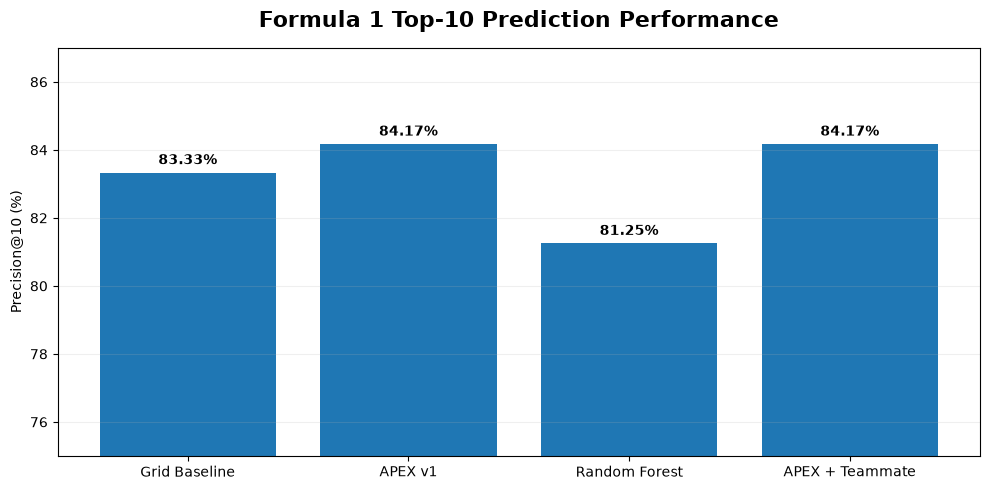

In [95]:
import matplotlib.pyplot as plt

models = [
    "Grid Baseline",
    "APEX v1",
    "Random Forest",
    "APEX + Teammate"
]

precision_at_10 = [
    83.33,
    84.17,
    81.25,
    84.17
]

plt.figure(figsize=(10, 5))

bars = plt.bar(
    models,
    precision_at_10
)

plt.title(
    "Formula 1 Top-10 Prediction Performance",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.ylabel("Precision@10 (%)")
plt.ylim(75, 87)

plt.grid(
    axis="y",
    alpha=0.2
)

for bar, value in zip(bars, precision_at_10):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.25,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

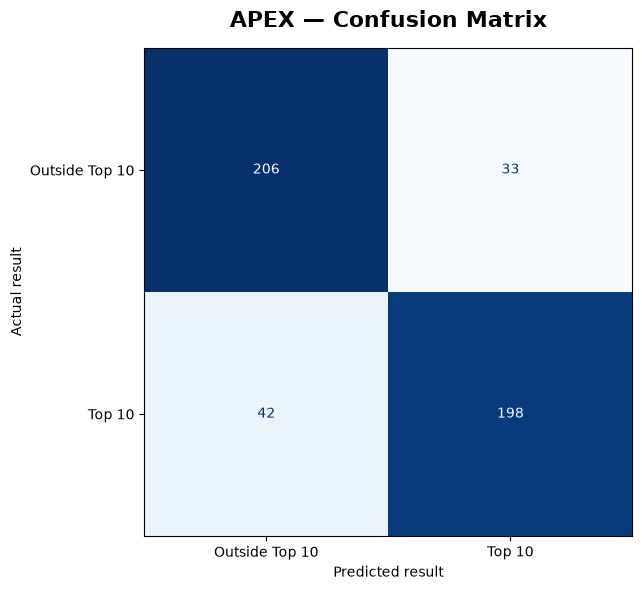

In [97]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test_tm,
    tm_pred
)

fig, ax = plt.subplots(figsize=(7, 6))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Outside Top 10",
        "Top 10"
    ]
)

display_cm.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False
)

ax.set_title(
    "APEX — Confusion Matrix",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Predicted result")
ax.set_ylabel("Actual result")

plt.tight_layout()
plt.show()

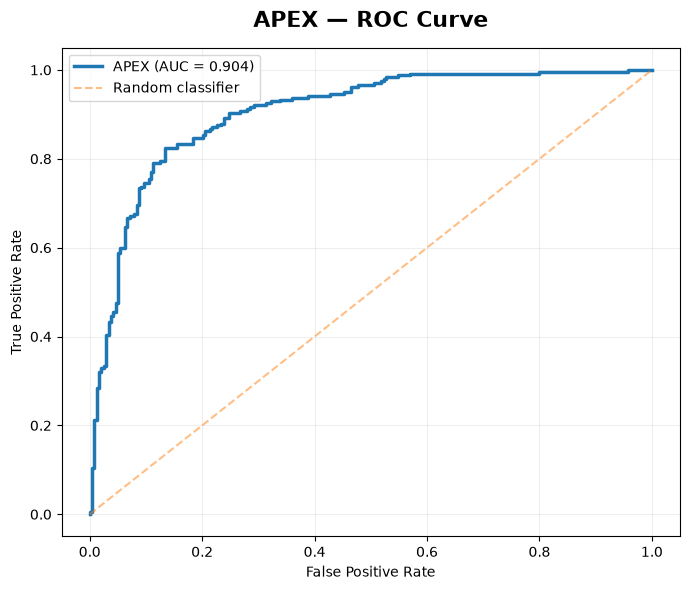

In [98]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(
    y_test_tm,
    tm_proba
)

auc = roc_auc_score(
    y_test_tm,
    tm_proba
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2.5,
    label=f"APEX (AUC = {auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    alpha=0.5,
    label="Random classifier"
)

plt.title(
    "APEX — ROC Curve",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

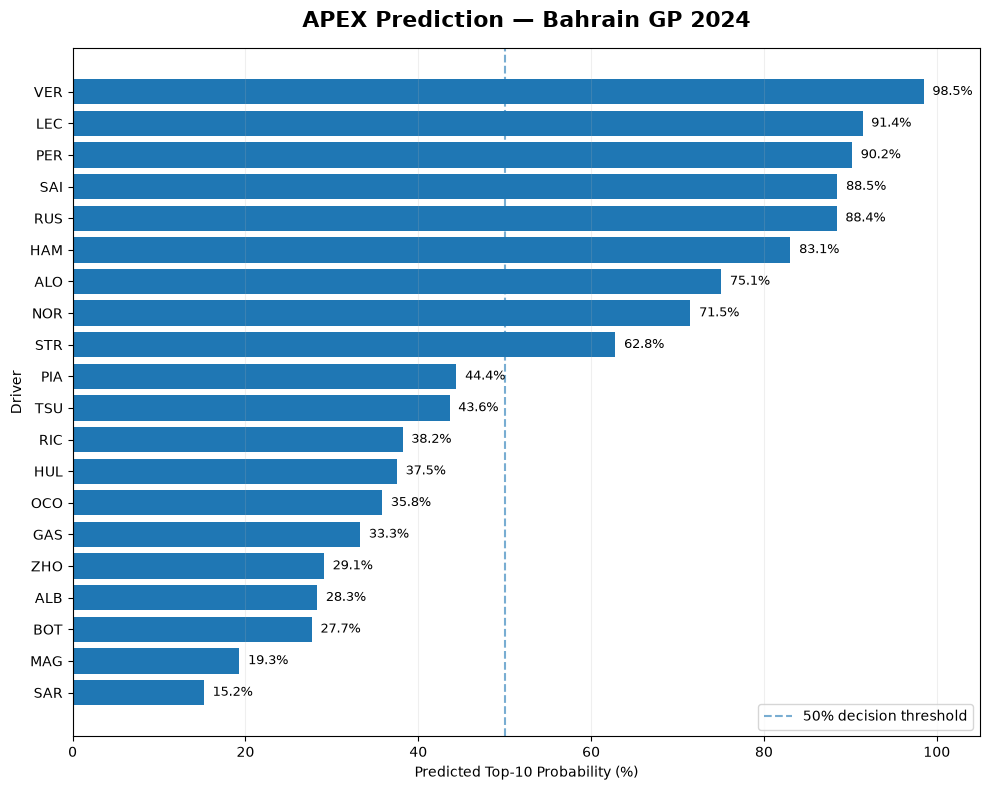

In [99]:
race_round = 1

race_plot = (
    tm_predictions[
        tm_predictions["round"] == race_round
    ]
    .sort_values(
        "probability",
        ascending=True
    )
    .copy()
)

plt.figure(figsize=(10, 8))

bars = plt.barh(
    race_plot["driver"],
    race_plot["probability"] * 100
)

plt.axvline(
    50,
    linestyle="--",
    alpha=0.6,
    label="50% decision threshold"
)

plt.title(
    "APEX Prediction — Bahrain GP 2024",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Predicted Top-10 Probability (%)")
plt.ylabel("Driver")

plt.xlim(0, 105)

for bar, probability in zip(
    bars,
    race_plot["probability"]
):
    plt.text(
        probability * 100 + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{probability:.1%}",
        va="center",
        fontsize=9
    )

plt.legend()
plt.grid(
    axis="x",
    alpha=0.2
)

plt.tight_layout()
plt.show()

In [101]:
import json

all_2024_predictions = []

for round_number in sorted(tm_predictions["round"].unique()):
    race = (
        tm_predictions[
            tm_predictions["round"] == round_number
        ]
        .sort_values("probability", ascending=False)
        .copy()
    )

    drivers = []

    for rank, (_, row) in enumerate(race.iterrows(), start=1):
        drivers.append({
            "rank": rank,
            "driver": row["driver"],
            "name": row["driver_name"],
            "team": row["team"],
            "probability": round(float(row["probability"]) * 100, 2),
            "grid": int(row["grid_position"]) if pd.notna(row["grid_position"]) else None,
            "finish": int(row["finish_position"]) if pd.notna(row["finish_position"]) else None,
            "top10": int(row["top10"])
        })

    all_2024_predictions.append({
        "round": int(round_number),
        "drivers": drivers
    })

with open(
    "data/processed/f1_2024_predictions.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        all_2024_predictions,
        f,
        indent=2,
        ensure_ascii=False
    )

print("Saved all 2024 race predictions.")
print("Races:", len(all_2024_predictions))

Saved all 2024 race predictions.
Races: 24
